In [1]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

from tensorflow.keras import models
from tensorflow.keras import layers

In [2]:
DATASET_path = "./dataset/"
data_dir = pathlib.Path(DATASET_path)

In [3]:
train_ds, val_ds = tf.keras.utils.audio_dataset_from_directory(
    directory=data_dir,
    batch_size=64,
    validation_split=0.3,
    output_sequence_length=16000, #pas quiz juga 16000
    subset='both',
    seed=0
)

Found 6505 files belonging to 4 classes.
Using 4554 files for training.
Using 1951 files for validation.


In [4]:
label_names = train_ds.class_names
print("Label Names:", label_names)

Label Names: ['follow', 'learn', 'tree', 'visual']


In [5]:
def squeeze(audio, labels):
    audio = tf.squeeze(audio, axis=-1)
    return audio, labels

# Menjalankan function squeeze untuk batch setiap audionya
train_ds = train_ds.map(squeeze, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(squeeze, num_parallel_calls=tf.data.AUTOTUNE)

In [6]:
# batch index genap
test_ds = val_ds.shard(
    num_shards=2,
    index=0
)

# batch index ganjil
val_ds = val_ds.shard(
    num_shards=2,
    index=1
)

In [7]:
def get_spectogram(audio):
    spectogram = tf.signal.stft(audio, frame_length=255, frame_step=128)
    spectogram = tf.abs(spectogram)
    spectogram = spectogram[..., tf.newaxis]
    return spectogram

In [8]:
def make_spec_ds(ds):
    return ds.map(map_func = lambda audio, label
                  : (get_spectogram(audio), label))

In [9]:
train_spectogram_ds = make_spec_ds(train_ds)
val_spectogram_ds = make_spec_ds(val_ds)
test_spectogram_ds = make_spec_ds(test_ds)

In [10]:
for sample_spectogram, sample_label in train_spectogram_ds.take(1):
    input_shape = sample_spectogram.shape[1:]
    break

In [11]:
num_labels = len(label_names)

norm_layers = layers.Normalization()
norm_layers.adapt(data=train_spectogram_ds.map
                  (map_func=lambda spec, label : spec))

model = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Resizing(32, 32),
    norm_layers,
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2), strides=(2,2)),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2), strides=(2,2)),
    layers.Dropout(0.25),
    layers.Flatten(),
    
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    
    layers.Dense(num_labels),
])

In [12]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing (Resizing)         (None, 32, 32, 1)         0         
                                                                 
 normalization (Normalizatio  (None, 32, 32, 1)        3         
 n)                                                              
                                                                 
 conv2d (Conv2D)             (None, 30, 30, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 15, 15, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 13, 13, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 6, 6, 64)         0

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics = ['accuracy']
)

In [14]:
EPOCHS = 10

history = model.fit(
    train_spectogram_ds,
    validation_data = val_spectogram_ds,
    epochs = EPOCHS,
    callbacks =[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2)]
)

Epoch 1/10
72/72 [==============================] - 3s 28ms/step - loss: 0.8989 - accuracy: 0.6315 - val_loss: 0.6502 - val_accuracy: 0.7625
Epoch 2/10
72/72 [==============================] - 2s 26ms/step - loss: 0.5512 - accuracy: 0.8076 - val_loss: 0.4567 - val_accuracy: 0.8656
Epoch 3/10
72/72 [==============================] - 2s 26ms/step - loss: 0.4311 - accuracy: 0.8555 - val_loss: 0.3814 - val_accuracy: 0.8750
Epoch 4/10
72/72 [==============================] - 2s 27ms/step - loss: 0.3385 - accuracy: 0.8808 - val_loss: 0.3479 - val_accuracy: 0.8958
Epoch 5/10
72/72 [==============================] - 2s 27ms/step - loss: 0.3026 - accuracy: 0.8975 - val_loss: 0.3014 - val_accuracy: 0.9073
Epoch 6/10
72/72 [==============================] - 2s 27ms/step - loss: 0.2633 - accuracy: 0.9124 - val_loss: 0.3295 - val_accuracy: 0.8969
Epoch 7/10
72/72 [==============================] - 2s 27ms/step - loss: 0.2321 - accuracy: 0.9212 - val_loss: 0.2596 - val_accuracy: 0.9125
Epoch 8/10
72

In [15]:
y_pred = model.predict(test_spectogram_ds)
y_pred = tf.argmax(y_pred,axis=1)

16/16 [==============================] - 0s 17ms/step


In [16]:
def convert_to_label(labels):
    return [label_names[label.numpy()] for label in labels]

y_pred = convert_to_label(y_pred)
y_true = convert_to_label(tf.concat([label for _, label in test_spectogram_ds], axis=0))

In [17]:
for idx, (true_label, pred_label) in enumerate(zip(y_true, y_pred)):
    print(f"Data {idx}: Original -> {true_label}, Predicted -> {pred_label}")

Data 0: Original -> tree, Predicted -> tree
Data 1: Original -> learn, Predicted -> learn
Data 2: Original -> tree, Predicted -> tree
Data 3: Original -> tree, Predicted -> tree
Data 4: Original -> tree, Predicted -> tree
Data 5: Original -> visual, Predicted -> visual
Data 6: Original -> tree, Predicted -> tree
Data 7: Original -> visual, Predicted -> visual
Data 8: Original -> learn, Predicted -> learn
Data 9: Original -> visual, Predicted -> visual
Data 10: Original -> visual, Predicted -> visual
Data 11: Original -> follow, Predicted -> follow
Data 12: Original -> learn, Predicted -> learn
Data 13: Original -> tree, Predicted -> tree
Data 14: Original -> tree, Predicted -> tree
Data 15: Original -> visual, Predicted -> visual
Data 16: Original -> tree, Predicted -> tree
Data 17: Original -> tree, Predicted -> tree
Data 18: Original -> tree, Predicted -> tree
Data 19: Original -> follow, Predicted -> follow
Data 20: Original -> tree, Predicted -> tree
Data 21: Original -> visual, Pr

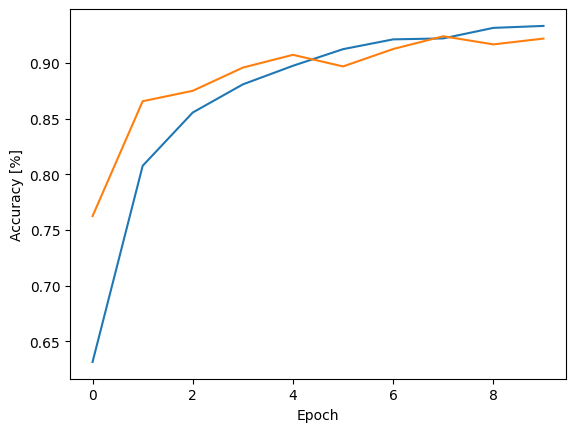

In [18]:
metrics = history.history
plt.plot(history.epoch,metrics['accuracy'])
plt.plot(history.epoch,metrics['val_accuracy'])
plt.xlabel("Epoch")
plt.ylabel("Accuracy [%]")
plt.show()